## Build a pulse sequence from scratch

The following two constructions implement reset → X → measurement on physical q1 without a circuit, registry, or target. Barriers synchronize the flux, drive, and readout channels between stages.

These numerical values illustrate construction only. Reset and X behavior requires device-calibrated amplitudes, durations, and frequencies; frequencies here use the default zero reference.


In [ ]:
from mb_client.pulse import (
    PulseSequence, Pulse, NetZero, Idle, Drag, ErrorFunction,
    FluxChannel, DriveChannel, ReadoutChannel,
)

# Channels for physical qubit q1.
flux = FluxChannel(1)
drive = DriveChannel(1)
readout = ReadoutChannel(1)
channels = (flux, drive, readout)

reset_pulse = Pulse(NetZero(duration=200e-9, amplitude=0.2, sigma=10e-9))
reset_pad = Pulse(Idle(40e-9))
x_pulse = Pulse(Drag(duration=40e-9, amplitude=0.1, beta=0.0))
readout_pulse = Pulse(ErrorFunction(duration=1e-6, amplitude=0.1, sigma=10e-9))


### 1. Ordinary construction

Create a sequence and append operations explicitly.


In [2]:
sequence_plain = PulseSequence()

# Reset q1, then allow the flux pulse to settle.
sequence_plain.play(flux, reset_pulse)
sequence_plain.barrier(*channels)
sequence_plain.play(drive, reset_pad)
sequence_plain.barrier(*channels)

# Apply an X pulse to q1.
sequence_plain.play(drive, x_pulse)
sequence_plain.barrier(*channels)

# Measure q1 into classical bit 0.
# Playback and acquisition start together on independent readout lanes.
sequence_plain.play(readout, readout_pulse)
sequence_plain.acquire(readout, duration=1e-6, clbit=0)


Acquire(channel=ReadoutChannel(qubit_index=1), duration=1e-06, digitizer_delay=0.0, demod_freq=0.0, data_form='DEMOD', name=None, clbit=0)

### 2. Context-manager construction

The `with` block returns the sequence itself. It remains available afterward; exiting does not automatically schedule it or suppress exceptions.


In [3]:
with PulseSequence() as sequence_with:
    # Reset q1, then allow the flux pulse to settle.
    sequence_with.play(flux, reset_pulse)
    sequence_with.barrier(*channels)
    sequence_with.play(drive, reset_pad)
    sequence_with.barrier(*channels)

    # Apply an X pulse to q1.
    sequence_with.play(drive, x_pulse)
    sequence_with.barrier(*channels)

    # Measure q1 into classical bit 0.
    # Playback and acquisition start together on independent readout lanes.
    sequence_with.play(readout, readout_pulse)
    sequence_with.acquire(readout, duration=1e-6, clbit=0)


### Compare and draw

Both constructions produce the same operations and scheduled start times.


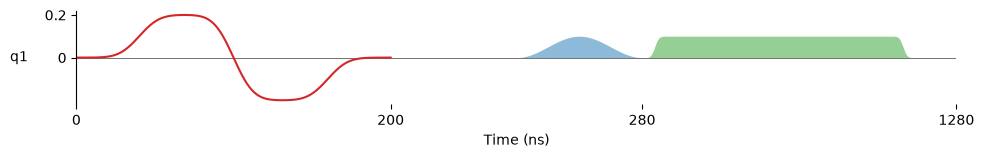

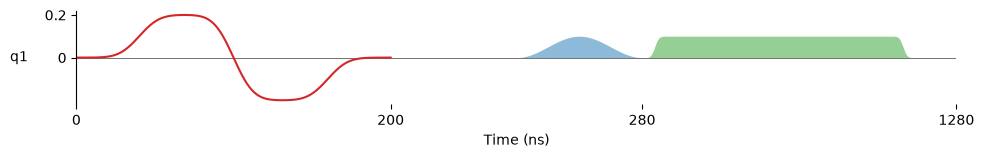

In [4]:
assert list(sequence_plain) == list(sequence_with)
schedule_plain = sequence_plain.schedule()
schedule_with = sequence_with.schedule()
assert [(type(e), e.channel, e.start, e.end) for e in schedule_plain] == [
    (type(e), e.channel, e.start, e.end) for e in schedule_with
]

figure_plain, axes_plain = schedule_plain.draw()
figure_with, axes_with = schedule_with.draw()
